## Task 1: Data Forensics & Cleaning

In [158]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('pima_modified.csv')

In [159]:
display(df.head(10))

,preg,plas,pres,skin,test,mass,pedi,age,class,hospital_id
0,6,980,58,?,?,34.0,0.430,43,0,958379
1,2,1120,75,?,0,35.7,0.148,21,0,621608
2,2,1080,64,?,0,30.8,0.158,21,0,830265
3,8,1070,80,?,?,24.6,0.856,34,0,924143
4,7,1360,90,?,0,29.9,0.210,50,0,995331
5,6,1030,72,?,190,37.7,0.324,55,0,212990
6,1,710,48,?,76,20.4,0.323,22,0,769416
7,0,1170,0,?,?,33.8,0.932,44,0,382017
8,4,1540,?,?,126,31.3,0.338,37,0,229350
9,5,1470,78,?,0,33.7,0.218,65,0,652370


In [160]:
print(df.shape)

(768, 10)


In [161]:
print(df.dtypes)

preg             int64
plas             int64
pres               str
skin               str
test               str
mass           float64
pedi           float64
age              int64
class            int64
hospital_id      int64
dtype: object


In [162]:
print((df == '?').sum())
df = df.replace('?', np.nan)
for col in ['pres', 'skin', 'test']:
    df[col] = pd.to_numeric(df[col])
print(df.isna().sum())

preg            0
plas            0
pres           38
skin           38
test           38
mass            0
pedi            0
age             0
class           0
hospital_id     0
dtype: int64
preg            0
plas            0
pres           38
skin           38
test           38
mass            0
pedi            0
age             0
class           0
hospital_id     0
dtype: int64


In [163]:
print('--------------------------------')
print(df[['pres', 'skin', 'test']].isna().all(axis=1).sum()) # returns 0: no rows have all three columns as NaN
print('--------------------------------')
print(df[['pres', 'skin', 'test']].isna().any(axis=1).sum()) # returns 108: 108 rows have at least one of the three columns as NaN

--------------------------------
0
--------------------------------
108


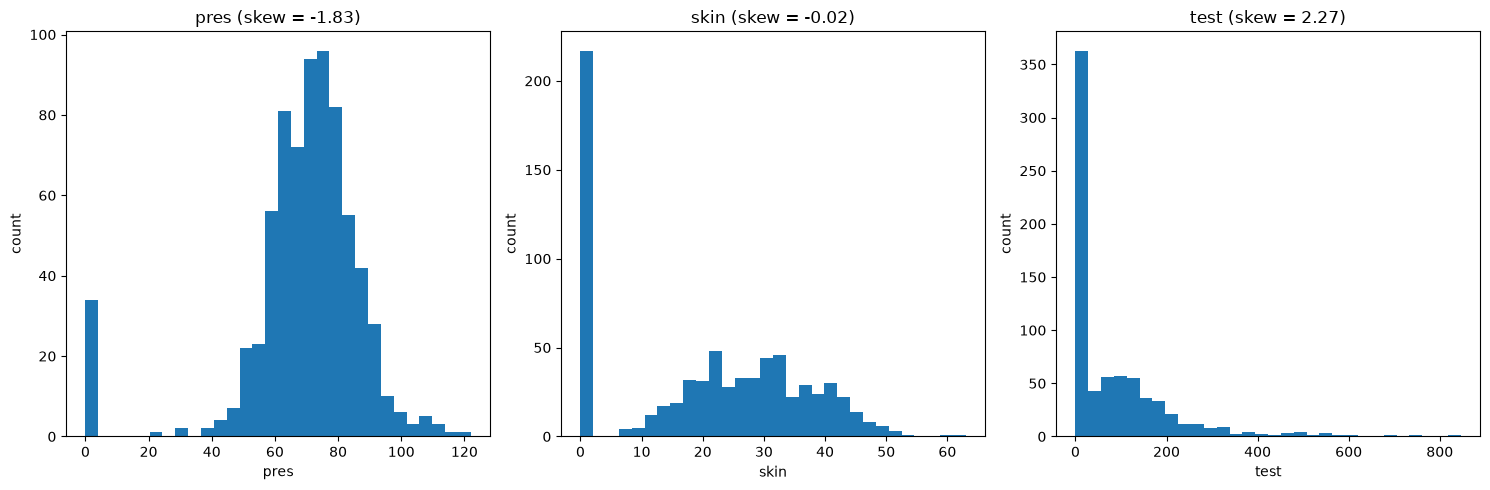

plas      5
pres     34
skin    217
test    354
mass     11
dtype: int64


In [164]:
df[['pres', 'skin', 'test']].skew()

cols = ['pres', 'skin', 'test']

fig, axes = plt.subplots(1, 3, figsize=(15, 5)) 

for ax, col in zip(axes, cols):
    ax.hist(df[col].dropna(), bins=30) # dropna() is used to ignore NaN values in the histogram; histograms can't plot NaN values
    ax.set_title(f"{col} (skew = {df[col].skew():.2f})")
    ax.set_xlabel(col)
    ax.set_ylabel('count')

plt.tight_layout()
plt.show()
print((df[['plas', 'pres', 'skin', 'test', 'mass']] == 0).sum())